# Cats and Dogs++ — multi-label pet classification
**Liliia Yaroshenko, AI28**

Kaggle competition: [Cats and Dogs++](https://www.kaggle.com/competitions/cats-and-dogs/overview) · Experiment tracking: [W&B project](https://wandb.ai/lyaroshenko-kse/cats-and-dogs-pp) · Full write-up: `report.md`

Each photo has five binary labels: two species (`Cat`, `Dog`) and three specific pets (`Moris`, `Motya`, `Biatrix`). The metric is macro F1.

## 1. Setup

In [ ]:
%pip install -q timm lightning wandb imagehash grad-cam

In [ ]:
import os, glob, json, gc, warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import imagehash

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms as T
import timm
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint, LearningRateMonitor
import wandb

from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import f1_score, average_precision_score, roc_auc_score

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

from kaggle_secrets import UserSecretsClient

CLASSES = ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']
RARE = ['Moris', 'Motya', 'Biatrix']
ID_COL = 'image_id'

DATA_DIR = os.path.dirname(glob.glob('/kaggle/input/**/train.csv', recursive=True)[0])
TRAIN_CSV = f'{DATA_DIR}/train.csv'
TEST_CSV = f'{DATA_DIR}/test.csv'
SAMPLE_SUB = f'{DATA_DIR}/sample_submission.csv'

OUT = '/kaggle/working'
FOLDS_CSV = f'{OUT}/folds.csv'
RESULTS_CSV = f'{OUT}/results.csv'
PREDS_DIR = f'{OUT}/preds'
CKPT_DIR = f'{OUT}/checkpoints'
os.makedirs(PREDS_DIR, exist_ok=True)

rng = np.random.default_rng(42)


def index_dir(folder):
    return {os.path.splitext(f)[0]: os.path.join(folder, f) for f in os.listdir(folder)}


TRAIN_FILES = index_dir(f'{DATA_DIR}/train')
TEST_FILES = index_dir(f'{DATA_DIR}/test')


def find_path(files, img_id):
    return files[os.path.splitext(str(img_id))[0]]


wandb.login(key=UserSecretsClient().get_secret('WANDB_API_KEY'))

## 2. Exploratory data analysis

### 2.1 Label tables

In [ ]:
df = pd.read_csv(TRAIN_CSV)
Y = df[CLASSES].astype(int).values
n = len(df)
df.head()

,image_id,Cat,Dog,Moris,Motya,Biatrix
0,7e17a6e589f9c891857b32bbb3652d19b7d5a215,0,0,0,0,0
1,7ad97bd6c7ef98373f43f2bbd1e41b2bbff4687e,1,0,0,0,0
2,d29be872d012d8766c5942847d1d721788fd9511,0,1,0,0,0
3,bec7727bfc721629997d782ec020ee555990128f,0,1,0,0,0
4,58bb7362153d945f48721004bc8fb2ee73a855b0,0,1,0,0,0


In [ ]:
pos = pd.DataFrame({'positives': Y.sum(0), '%': (Y.mean(0) * 100).round(2)}, index=CLASSES)
display(pos)

k = Y.sum(1)
per_img = pd.Series(k).value_counts().sort_index().rename_axis('labels_per_image').to_frame('n_images')
per_img['%'] = (per_img['n_images'] / n * 100).round(2)
display(per_img)

co = pd.DataFrame(Y.T @ Y, index=CLASSES, columns=CLASSES)
display(co)

cond = (co.div(np.diag(co), axis=0) * 100).round(1)
display(cond)

,positives,%
Cat,5077,41.41
Dog,5025,40.99
Moris,56,0.46
Motya,42,0.34
Biatrix,41,0.33


,n_images,%
labels_per_image,,
0,2162,17.63
1,9973,81.35
2,111,0.91
3,10,0.08
4,4,0.03


,Cat,Dog,Moris,Motya,Biatrix
Cat,5077,4,56,42,4
Dog,4,5025,4,0,41
Moris,56,4,56,10,4
Motya,42,0,10,42,0
Biatrix,4,41,4,0,41


,Cat,Dog,Moris,Motya,Biatrix
Cat,100.0,0.1,1.1,0.8,0.1
Dog,0.1,100.0,0.1,0.0,0.8
Moris,100.0,7.1,100.0,17.9,7.1
Motya,100.0,0.0,23.8,100.0,0.0
Biatrix,9.8,100.0,9.8,0.0,100.0


**Conclusion:** the data is strongly imbalanced: Cat 41.4% and Dog 41.0%, while Moris, Motya and Biatrix have only 41–56 photos each (<0.5%) and 17.6% of photos have no label. Every Moris and Motya is a Cat and every Biatrix is a Dog (100%), so the three rare classes decide 60% of the macro metric.

### 2.2 Image grid: rare classes, ordinary cats and empty photos

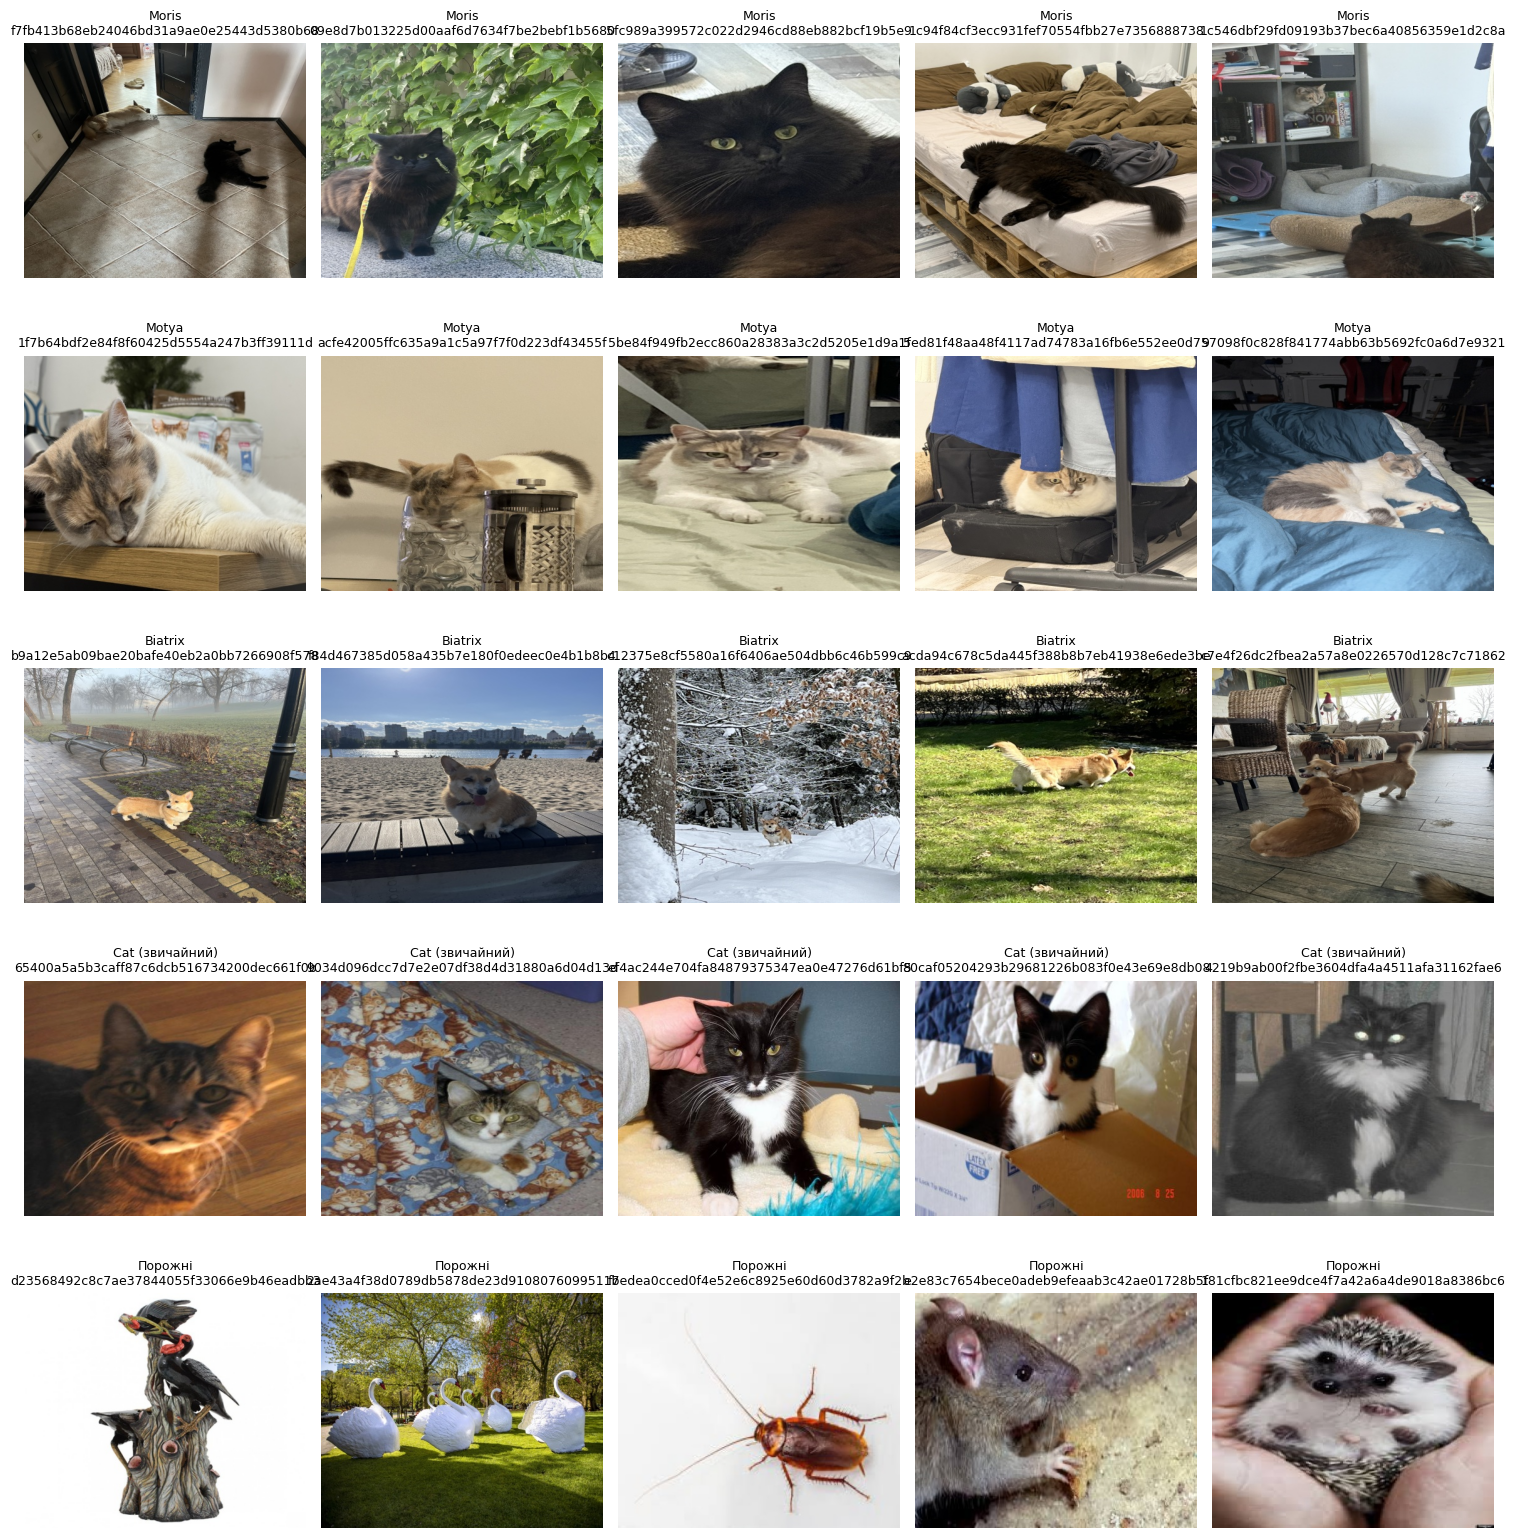

In [ ]:
groups = {r: df.index[df[r] == 1] for r in RARE}
groups['Cat (ordinary)'] = df.index[(df['Cat'] == 1) & (df[RARE + ['Dog']].sum(1) == 0)]
groups['Empty'] = df.index[k == 0]

fig, axes = plt.subplots(len(groups), 5, figsize=(15, 3.2 * len(groups)))
for i, (name, idx) in enumerate(groups.items()):
    pick = rng.choice(idx, size=min(5, len(idx)), replace=False)
    for j in range(5):
        ax = axes[i, j]
        ax.axis('off')
        if j < len(pick):
            img_id = df.loc[pick[j], ID_COL]
            with Image.open(find_path(TRAIN_FILES, img_id)) as im:
                ax.imshow(im.convert('RGB'))
            ax.set_title(f'{name}\n{img_id}', fontsize=9)
plt.tight_layout()
plt.savefig(f'{OUT}/step9_grid.png', dpi=100, bbox_inches='tight')
plt.show()

**Conclusion:** Moris, Motya and Biatrix are specific, recognisable animals, and the "empty" photos are not blank frames but distractors (birds, swan sculptures, insects, rats, hedgehogs), so the model has to learn individual pets, not just species.

### 2.3 Image sizes

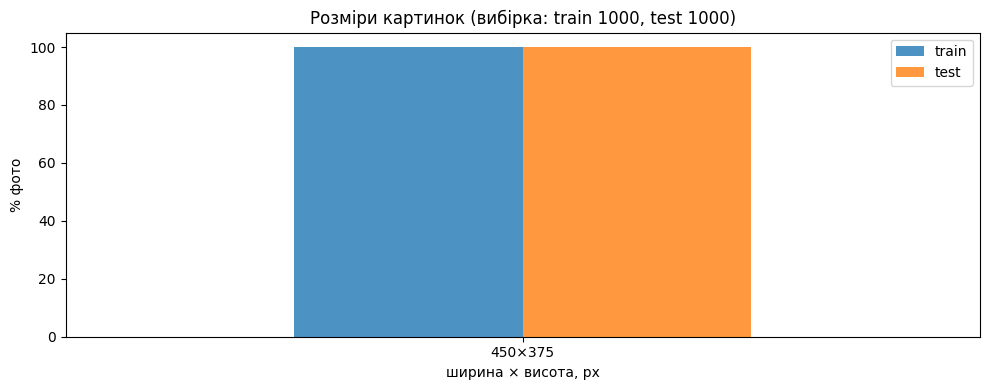

In [ ]:
def sizes(paths):
    out = []
    for p in paths:
        with Image.open(p) as im:
            out.append(im.size)
    return np.array(out)


tr_list, te_list = list(TRAIN_FILES.values()), list(TEST_FILES.values())
tr = sizes(rng.choice(tr_list, min(1000, len(tr_list)), replace=False))
te = sizes(rng.choice(te_list, min(1000, len(te_list)), replace=False))

tr_s = pd.Series([f'{w}×{h}' for w, h in tr]).value_counts(normalize=True) * 100
te_s = pd.Series([f'{w}×{h}' for w, h in te]).value_counts(normalize=True) * 100
sz = (pd.DataFrame({'train': tr_s, 'test': te_s})
        .fillna(0).sort_values('train', ascending=False).head(15))

ax = sz.plot.bar(figsize=(10, 4), rot=0, alpha=.8)
ax.set_ylabel('% of images')
ax.set_xlabel('width × height, px')
ax.set_title(f'Image sizes (sample: {len(tr)} train, {len(te)} test)')
plt.tight_layout()
plt.savefig(f'{OUT}/step10_sizes.png', dpi=100, bbox_inches='tight')
plt.show()

**Conclusion:** all 2,000 sampled photos are 450×375 (aspect ratio 1.20) in both train and test, so resizing to 224 only downsamples the images and the two size distributions are identical.

## 3. Validation folds

### 3.1 Duplicate groups (perceptual hash)

In [ ]:
NEAR_THR = 8

paths = df[ID_COL].map(lambda i: find_path(TRAIN_FILES, i))


def phash(p):
    with Image.open(p) as im:
        return imagehash.phash(im)


with ThreadPoolExecutor(8) as ex:
    hashes = list(tqdm(ex.map(phash, paths), total=n, desc='phash'))
df['phash'] = [str(h) for h in hashes]

parent = np.arange(n)


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra


for idx in df.groupby('phash').indices.values():
    for j in idx[1:]:
        union(idx[0], j)

rare_idx = np.where(df[RARE].sum(1) > 0)[0]
bits = np.array([hashes[i].hash.flatten() for i in rare_idx])
dist = (bits[:, None, :] != bits[None, :, :]).sum(-1)
ii, jj = np.where(np.triu(dist <= NEAR_THR, k=1))
for a, b in zip(ii, jj):
    union(rare_idx[a], rare_idx[b])

df['group'] = pd.factorize(np.array([find(i) for i in range(n)]))[0]

**Conclusion:** 124 groups of exact duplicates (248 photos) and 3 near-duplicate pairs among the 125 rare-class photos were found, giving 12,134 groups for 12,260 photos (252 photos have a "twin"), so identical frames cannot end up in both train and validation.

### 3.2 Five folds

In [ ]:
K, SEED = 5, 42
df['combo'] = df[CLASSES].astype(int).astype(str).agg(''.join, axis=1)
fold = np.full(n, -1)

is_rare = df[RARE].sum(1) > 0
rg = df[is_rare].groupby('group')[RARE].sum()
rg = rg.sample(frac=1, random_state=SEED)
rg = rg.loc[rg.sum(1).sort_values(ascending=False, kind='stable').index]
expected = df[RARE].sum().values / K
cnt = np.zeros((K, len(RARE)))
rare_fold = {}
for g, v in zip(rg.index, rg.values):
    delta = [((cnt[f] + v - expected) ** 2).sum() - ((cnt[f] - expected) ** 2).sum() for f in range(K)]
    f = int(np.argmin(delta))
    cnt[f] += v
    rare_fold[g] = f
rare_rows = df['group'].isin(rare_fold)
fold[rare_rows.values] = df.loc[rare_rows, 'group'].map(rare_fold).values

rest = df[~rare_rows]
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    sg = StratifiedGroupKFold(n_splits=K, shuffle=True, random_state=SEED)
    for f, (_, va) in enumerate(sg.split(rest, rest['combo'], rest['group'])):
        fold[rest.index[va]] = f
df['fold'] = fold

assert (df['fold'] >= 0).all()
assert df.groupby('group')['fold'].nunique().max() == 1, 'a duplicate group is split between folds'

tab = df.groupby('fold')[CLASSES].sum()
tab['n_photos'] = df.groupby('fold').size()
tab['empty'] = df[df[CLASSES].sum(1) == 0].groupby('fold').size()
display(tab)

df[[ID_COL, *CLASSES, 'combo', 'group', 'fold']].to_csv(FOLDS_CSV, index=False)

,Cat,Dog,Moris,Motya,Biatrix,n_photos,empty
fold,,,,,,,
0,1017,998,12,9,9,2450,437
1,1032,995,11,9,8,2451,424
2,1004,1000,11,8,8,2459,456
3,1019,1024,11,8,8,2444,402
4,1005,1008,11,8,8,2456,443


**Conclusion:** five folds of 2,444–2,459 photos each: groups with rare classes were placed greedily and the rest split by `StratifiedGroupKFold(random_state=42)`, so every fold has 8–12 examples of each rare class, no group is split, and fold 0 serves as the shared validation set for all experiments.

## 4. Training pipeline

### 4.1 Transforms and dataset

In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


def get_transforms(img_size, train):
    if train:
        return T.Compose([
            T.RandomResizedCrop(img_size, scale=(0.5, 1.0)),
            T.RandomHorizontalFlip(),
            T.ToTensor(),
            T.Normalize(MEAN, STD),
        ])
    return T.Compose([
        T.Resize(img_size),
        T.CenterCrop(img_size),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])


class PetDataset(Dataset):
    def __init__(self, paths, labels=None, transform=None):
        self.paths = list(paths)
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        img = self.transform(img)
        if self.labels is None:
            return img
        return img, torch.tensor(self.labels[i], dtype=torch.float32)

**Conclusion:** the dataset returns a 224×224 image and five labels; training uses a random crop (at least 50% of the area, so the pet is not cut out) and a horizontal flip, while validation and test use a deterministic centre crop.

### 4.2 DataModule

In [ ]:
class PetDataModule(L.LightningDataModule):
    def __init__(self, img_size=224, batch_size=64, oversample=1, num_workers=4):
        super().__init__()
        self.img_size = img_size
        self.batch_size = batch_size
        self.oversample = oversample
        self.num_workers = num_workers

    def setup(self, stage=None):
        folds = pd.read_csv(FOLDS_CSV)
        test = pd.read_csv(TEST_CSV)

        self.train_df = folds[folds['fold'] != 0].reset_index(drop=True)
        self.val_df = folds[folds['fold'] == 0].reset_index(drop=True)
        self.test_ids = test.iloc[:, 0].tolist()

        self.train_ds = PetDataset(
            [find_path(TRAIN_FILES, i) for i in self.train_df[ID_COL]],
            self.train_df[CLASSES].values,
            get_transforms(self.img_size, train=True))
        self.val_ds = PetDataset(
            [find_path(TRAIN_FILES, i) for i in self.val_df[ID_COL]],
            self.val_df[CLASSES].values,
            get_transforms(self.img_size, train=False))
        self.test_ds = PetDataset(
            [find_path(TEST_FILES, i) for i in self.test_ids],
            None,
            get_transforms(self.img_size, train=False))

    def train_dataloader(self):
        if self.oversample > 1:
            is_rare = self.train_df[RARE].sum(axis=1) > 0
            weights = np.where(is_rare, self.oversample, 1.0)
            sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
            return DataLoader(self.train_ds, batch_size=self.batch_size, sampler=sampler,
                              num_workers=self.num_workers, drop_last=True)
        return DataLoader(self.train_ds, batch_size=self.batch_size, shuffle=True,
                          num_workers=self.num_workers, drop_last=True)

    def val_dataloader(self):
        return DataLoader(self.val_ds, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers)

    def test_dataloader(self):
        return DataLoader(self.test_ds, batch_size=self.batch_size, shuffle=False, num_workers=self.num_workers)

**Conclusion:** the DataModule uses fold 0 as validation and the other folds as training data, and has an optional oversampling of rare-class photos via `WeightedRandomSampler`.

### 4.3 Model with an optional custom block (GeM pooling + MLP head)

In [ ]:
class GeM(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        x = x.float().clamp(min=self.eps)
        x = x.pow(self.p).mean(dim=(2, 3))
        return x.pow(1.0 / self.p)


class PetModel(L.LightningModule):
    def __init__(self, config):
        super().__init__()
        self.save_hyperparameters(config)
        self.cfg = config

        if config.get('head', 'default') == 'gem':
            self.backbone = timm.create_model(config['model'], pretrained=True, num_classes=0, global_pool='')
            n_features = self.backbone.num_features
            self.pool = GeM()
            self.head = nn.Sequential(
                nn.Dropout(0.3),
                nn.Linear(n_features, 256),
                nn.ReLU(),
                nn.Linear(256, len(CLASSES)),
            )
        else:
            self.backbone = timm.create_model(config['model'], pretrained=True, num_classes=len(CLASSES))
            self.pool = None
            self.head = None

        self.loss_fn = nn.BCEWithLogitsLoss()
        self.val_probs, self.val_true = [], []

    def forward(self, x):
        if self.pool is None:
            return self.backbone(x)
        return self.head(self.pool(self.backbone(x)))

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log('train_loss', loss, prog_bar=True)
        if self.pool is not None:
            self.log('gem_p', self.pool.p.item())
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        self.log('val_loss', self.loss_fn(logits, y), prog_bar=True)
        self.val_probs.append(torch.sigmoid(logits).float().cpu())
        self.val_true.append(y.cpu())

    def on_validation_epoch_end(self):
        probs = torch.cat(self.val_probs).numpy()
        true = torch.cat(self.val_true).numpy().astype(int)
        self.val_probs, self.val_true = [], []

        f1 = f1_score(true, (probs > 0.5).astype(int), average='macro', zero_division=0)
        ap = average_precision_score(true, probs, average=None)
        self.log('val_f1', f1, prog_bar=True)
        self.log('val_map', ap.mean(), prog_bar=True)
        for c, v in zip(CLASSES, ap):
            self.log(f'val_ap_{c}', v)

    def predict_step(self, batch, batch_idx):
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        return torch.sigmoid(self(x)).float().cpu()

    def configure_optimizers(self):
        c = self.cfg
        if c['optimizer'] == 'adamw':
            opt = torch.optim.AdamW(self.parameters(), lr=c['lr'], weight_decay=c.get('weight_decay', 0.01))
        elif c['optimizer'] == 'sgd':
            opt = torch.optim.SGD(self.parameters(), lr=c['lr'], momentum=0.9, weight_decay=c.get('weight_decay', 0.0))
        else:
            raise ValueError(f"unknown optimizer: {c['optimizer']}")

        steps = self.trainer.estimated_stepping_batches
        if c['scheduler'] == 'cosine':
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
        elif c['scheduler'] == 'onecycle':
            sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=c['lr'], total_steps=steps)
        elif c['scheduler'] == 'none':
            return opt
        else:
            raise ValueError(f"unknown scheduler: {c['scheduler']}")
        return {'optimizer': opt, 'lr_scheduler': {'scheduler': sched, 'interval': 'step'}}

**Conclusion:** the model is a timm backbone trained with BCE (labels are independent), it logs macro F1 at 0.5, macro mAP and per-class AP every epoch, and `head='gem'` swaps the default pooling and classifier for a learnable GeM pooling and a small MLP head.

### 4.4 Training run

In [ ]:
def run(config):
    L.seed_everything(42)
    exp_id = config['exp_id']

    dm = PetDataModule(config['img_size'], config['batch_size'], config.get('oversample', 1))
    model = PetModel(config)

    logger = WandbLogger(project='cats-and-dogs-pp', name=exp_id, config=config)
    logger.watch(model, log='gradients', log_freq=50)

    ckpt = ModelCheckpoint(monitor='val_map', mode='max', save_top_k=1, dirpath=CKPT_DIR, filename=exp_id)
    trainer = L.Trainer(
        max_epochs=config['epochs'],
        precision='16-mixed',
        logger=logger,
        callbacks=[ckpt, LearningRateMonitor(logging_interval='step')],
        num_sanity_val_steps=0,
    )
    trainer.fit(model, datamodule=dm)

    val_probs = torch.cat(trainer.predict(model, dataloaders=dm.val_dataloader(), ckpt_path='best')).numpy()
    test_probs = torch.cat(trainer.predict(model, dataloaders=dm.test_dataloader(), ckpt_path='best')).numpy()

    np.save(f'{PREDS_DIR}/{exp_id}_val.npy', val_probs)
    np.save(f'{PREDS_DIR}/{exp_id}_test.npy', test_probs)
    np.save(f'{PREDS_DIR}/val_true.npy', dm.val_df[CLASSES].values)

    wandb.finish()
    return val_probs, test_probs

**Conclusion:** `run(config)` trains one experiment, keeps the epoch with the best `val_map` and saves its validation and test probabilities to `preds/`, so thresholds, ensembles and error analysis need no retraining.

### 4.5 Thresholds, post-processing and submission

In [ ]:
def apply_thresholds(probs, thresholds):
    thr = np.array([thresholds[c] for c in CLASSES])
    pred = (probs >= thr).astype(int)
    CAT, DOG, MORIS, MOTYA, BIATRIX = 0, 1, 2, 3, 4
    pred[:, CAT] = pred[:, CAT] | pred[:, MORIS] | pred[:, MOTYA]
    pred[:, DOG] = pred[:, DOG] | pred[:, BIATRIX]
    return pred


def make_submission(test_probs, thresholds, path=f'{OUT}/submission.csv'):
    test = pd.read_csv(TEST_CSV)
    pred = apply_thresholds(test_probs, thresholds)

    sub = pd.DataFrame(pred, columns=CLASSES)
    sub.insert(0, 'image_id', test.iloc[:, 0].values)

    sample = pd.read_csv(SAMPLE_SUB)
    assert list(sub.columns) == ['image_id', 'Cat', 'Dog', 'Moris', 'Motya', 'Biatrix'], sub.columns
    assert list(sub.columns) == list(sample.columns), f'columns differ from sample: {list(sample.columns)}'
    assert len(sub) == len(sample), f'{len(sub)} rows, sample has {len(sample)}'
    assert set(sub['image_id']) == set(sample.iloc[:, 0]), 'ids differ from sample_submission'

    sub.to_csv(path, index=False)
    return sub

In [ ]:
def pick_thresholds(val_probs, val_true):
    grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
    rare_idx = [CLASSES.index(c) for c in RARE]

    mean_f1 = []
    for t in grid:
        f1s = [f1_score(val_true[:, i], (val_probs[:, i] >= t).astype(int), zero_division=0) for i in rare_idx]
        mean_f1.append(np.mean(f1s))
    best_t = grid[int(np.argmax(mean_f1))]
    thresholds = {'Cat': 0.5, 'Dog': 0.5, 'Moris': best_t, 'Motya': best_t, 'Biatrix': best_t}

    pred_05 = apply_thresholds(val_probs, {c: 0.5 for c in CLASSES})
    pred_thr = apply_thresholds(val_probs, thresholds)
    table = pd.DataFrame({
        'F1 @0.5': [f1_score(val_true[:, i], pred_05[:, i], zero_division=0) for i in range(5)],
        'F1 @thr': [f1_score(val_true[:, i], pred_thr[:, i], zero_division=0) for i in range(5)],
        'thr': [thresholds[c] for c in CLASSES],
    }, index=CLASSES)
    table.loc['MACRO'] = [table['F1 @0.5'].mean(), table['F1 @thr'].mean(), np.nan]
    display(table.round(3))
    return thresholds, table

**Conclusion:** Cat and Dog use threshold 0.5, the three rare classes share one threshold tuned on fold 0 (a separate threshold per class would overfit ~9 examples), post-processing forces Moris/Motya → Cat and Biatrix → Dog, and the submission columns and id order are checked against `sample_submission.csv`.

### 4.6 Experiment log

In [ ]:
def add_result(config, val_probs):
    val_true = np.load(f'{PREDS_DIR}/val_true.npy')
    thresholds, table = pick_thresholds(val_probs, val_true)
    ap = average_precision_score(val_true, val_probs, average=None)
    row = {
        'exp_id': config['exp_id'],
        'change': config.get('note', ''),
        'val_map': round(ap.mean(), 4),
        **{f'AP_{c}': round(v, 4) for c, v in zip(CLASSES, ap)},
        'F1@0.5': round(table.loc['MACRO', 'F1 @0.5'], 4),
        'rare_thr': thresholds['Moris'],
        'F1@thr': round(table.loc['MACRO', 'F1 @thr'], 4),
        'LB': np.nan,
        'config': json.dumps(config, ensure_ascii=False),
    }
    res = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
    if len(res):
        res = res[res['exp_id'] != config['exp_id']]
    res = pd.concat([res, pd.DataFrame([row])], ignore_index=True)
    res.to_csv(RESULTS_CSV, index=False)
    return thresholds


def experiment(config):
    val_probs, test_probs = run(config)
    thresholds = add_result(config, val_probs)
    make_submission(test_probs, thresholds, path=f"{OUT}/sub_{config['exp_id']}.csv")
    gc.collect()
    torch.cuda.empty_cache()


def set_lb(exp_id, score):
    res = pd.read_csv(RESULTS_CSV)
    res.loc[res['exp_id'] == exp_id, 'LB'] = score
    res.to_csv(RESULTS_CSV, index=False)


def show_results():
    display(pd.read_csv(RESULTS_CSV).drop(columns='config'))


def best_config(exp_ids):
    res = pd.read_csv(RESULTS_CSV)
    res = res[res['exp_id'].isin(exp_ids)]
    best = res.loc[res['val_map'].idxmax()]
    return json.loads(best['config']), best['exp_id']

**Conclusion:** every experiment adds one row to `results.csv` (val mAP, per-class AP, F1 at 0.5 and at the tuned threshold, LB), which serves as the parameter-tuning log alongside the W&B runs.

## 5. Experiments

Each experiment changes one thing relative to the baseline; exp06 and exp07 start from the best previous configuration (chosen by validation mAP).

### exp01 — baseline: ResNet-18, AdamW, lr 1e-4, cosine, 3 epochs

In [ ]:
BASE = dict(exp_id='exp01', model='resnet18', img_size=224, batch_size=64,
            optimizer='adamw', lr=1e-4, weight_decay=1e-2, scheduler='cosine',
            epochs=3, oversample=1, head='default', note='baseline')
experiment(BASE)

,F1 @0.5,F1 @thr,thr
Cat,0.958,0.951,0.5
Dog,0.952,0.950,0.5
Moris,0.000,0.207,0.2
Motya,0.000,0.049,0.2
Biatrix,0.000,0.129,0.2
MACRO,0.382,0.457,NaN


**Conclusion:** the baseline separates cats and dogs almost perfectly (AP 0.99) but barely learns the rare classes (AP 0.02–0.09); at threshold 0.5 it predicts no rare animal (macro F1 0.38), the shared threshold 0.20 lifts it to 0.46, and LB 0.413 confirms that the pipeline is correct.

### exp02 — learning rate 3e-4

In [ ]:
experiment({**BASE, 'exp_id': 'exp02', 'lr': 3e-4, 'note': 'lr 3e-4'})

,F1 @0.5,F1 @thr,thr
Cat,0.982,0.981,0.5
Dog,0.979,0.978,0.5
Moris,0.000,0.632,0.1
Motya,0.000,0.235,0.1
Biatrix,0.000,0.250,0.1
MACRO,0.392,0.615,NaN


**Conclusion:** the baseline was learning too slowly: with lr 3e-4 val mAP rises from 0.43 to 0.65 and Moris AP from 0.09 to 0.62.

### exp03 — SGD with momentum (lr 1e-2, weight decay 1e-4)

In [ ]:
experiment({**BASE, 'exp_id': 'exp03', 'optimizer': 'sgd', 'lr': 1e-2, 'weight_decay': 1e-4,
            'note': 'SGD momentum 0.9, lr 1e-2'})

,F1 @0.5,F1 @thr,thr
Cat,0.949,0.944,0.50
Dog,0.940,0.938,0.50
Moris,0.000,0.000,0.05
Motya,0.000,0.000,0.05
Biatrix,0.000,0.000,0.05
MACRO,0.378,0.376,NaN


**Conclusion:** the worst run (val mAP 0.40, rare-class AP ~0.01): in 3 epochs SGD did not move the rare classes at all, so AdamW is clearly better for short fine-tuning here.

### exp04 — OneCycle scheduler instead of cosine

In [ ]:
experiment({**BASE, 'exp_id': 'exp04', 'scheduler': 'onecycle', 'note': 'OneCycle instead of cosine'})

,F1 @0.5,F1 @thr,thr
Cat,0.959,0.951,0.5
Dog,0.955,0.951,0.5
Moris,0.000,0.207,0.2
Motya,0.000,0.048,0.2
Biatrix,0.000,0.114,0.2
MACRO,0.383,0.454,NaN


**Conclusion:** OneCycle equals the baseline (val mAP 0.433 vs 0.429, within noise) because it used the same maximum lr of 1e-4, so only the shape of the schedule changed.

### exp05 — oversampling of rare classes ×10

In [ ]:
experiment({**BASE, 'exp_id': 'exp05', 'oversample': 10, 'note': 'oversampling rare ×10'})

,F1 @0.5,F1 @thr,thr
Cat,0.964,0.958,0.5
Dog,0.948,0.946,0.5
Moris,0.000,0.560,0.3
Motya,0.000,0.160,0.3
Biatrix,0.000,0.231,0.3
MACRO,0.382,0.571,NaN


**Conclusion:** showing rare pets more often helps (val mAP 0.59 vs 0.43), but the gain is smaller than from raising the learning rate.

### exp06 — EfficientNet-B0 with the best settings so far

In [ ]:
cfg, best_id = best_config(['exp01', 'exp02', 'exp03', 'exp04', 'exp05'])
experiment({**cfg, 'exp_id': 'exp06', 'model': 'efficientnet_b0',
            'note': f'efficientnet_b0 (settings {best_id})'})

,F1 @0.5,F1 @thr,thr
Cat,0.992,0.992,0.50
Dog,0.989,0.989,0.50
Moris,0.857,0.870,0.25
Motya,0.778,0.818,0.25
Biatrix,0.615,0.800,0.25
MACRO,0.846,0.894,NaN


**Conclusion:** EfficientNet-B0 with the settings of exp02 gives the largest improvement (val mAP 0.936 vs 0.652 for ResNet-18 with the same settings) and reaches LB 0.863.

### exp07 — custom block: GeM pooling + MLP head on the best model

In [ ]:
cfg, best_id = best_config(['exp01', 'exp02', 'exp03', 'exp04', 'exp05', 'exp06'])
experiment({**cfg, 'exp_id': 'exp07', 'head': 'gem',
            'note': f'GeM + head (base {best_id})'})

,F1 @0.5,F1 @thr,thr
Cat,0.996,0.996,0.5
Dog,0.991,0.992,0.5
Moris,0.737,0.690,0.2
Motya,0.000,0.720,0.2
Biatrix,0.714,0.941,0.2
MACRO,0.688,0.868,NaN


**Conclusion:** the custom GeM head matches the same model without it (val mAP 0.932 vs 0.936, within noise): it ranks Biatrix better (AP 0.97 vs 0.90) but Moris and Motya worse, and its probabilities are less confident (F1 at 0.5 is 0.69 vs 0.85).

### Summary of experiments

In [ ]:
display(pd.read_csv(RESULTS_CSV).drop(columns='config').sort_values('val_map', ascending=False))

,exp_id,change,val_map,AP_Cat,AP_Dog,AP_Moris,AP_Motya,AP_Biatrix,F1@0.5,rare_thr,F1@thr,LB
5,exp06,efficientnet_b0 (settings exp02),0.9362,0.9996,0.9990,0.9063,0.8763,0.8998,0.8463,0.25,0.8938,NaN
6,exp07,GeM + head (base exp06),0.9321,0.9998,0.9994,0.8777,0.8116,0.9722,0.6876,0.20,0.8677,NaN
1,exp02,lr 3e-4,0.6521,0.9986,0.9980,0.6158,0.2350,0.4131,0.3923,0.10,0.6151,NaN
4,exp05,oversampling rare ×10,0.5916,0.9919,0.9910,0.6230,0.1558,0.1961,0.3824,0.30,0.5711,NaN
3,exp04,OneCycle instead of cosine,0.4329,0.9926,0.9934,0.0996,0.0266,0.0525,0.3828,0.20,0.4543,NaN
0,exp01,baseline,0.4287,0.9919,0.9931,0.0887,0.0207,0.0490,0.3821,0.20,0.4571,0.4126
2,exp03,"SGD momentum 0.9, lr 1e-2",0.4004,0.9891,0.9855,0.0113,0.0037,0.0122,0.3777,0.05,0.3764,NaN


**Conclusion:** the best model is exp06 (val mAP 0.936, F1 0.894) and the worst is exp03 (SGD); the learning rate and the architecture matter most, while SGD, OneCycle at the same lr and the GeM head bring nothing.

## 6. Adversarial validation

In [ ]:
adv_rng = np.random.default_rng(42)
tr_paths = adv_rng.choice(list(TRAIN_FILES.values()), 3000, replace=False)
te_paths = adv_rng.choice(list(TEST_FILES.values()), 3000, replace=False)
adv_paths = np.r_[tr_paths, te_paths]
adv_labels = np.r_[np.zeros(3000), np.ones(3000)].reshape(-1, 1)

p_tr, p_va, y_tr, y_va = train_test_split(adv_paths, adv_labels, test_size=0.2,
                                          stratify=adv_labels[:, 0], random_state=42)
adv_train = DataLoader(PetDataset(p_tr, y_tr, get_transforms(224, train=True)),
                       batch_size=64, shuffle=True, num_workers=4, drop_last=True)
adv_val = DataLoader(PetDataset(p_va, y_va, get_transforms(224, train=False)),
                     batch_size=64, shuffle=False, num_workers=4)


class AdvModel(L.LightningModule):
    def __init__(self):
        super().__init__()
        self.net = timm.create_model('resnet18', pretrained=True, num_classes=1)
        self.loss_fn = nn.BCEWithLogitsLoss()

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self.net(x), y)
        self.log('train_loss', loss, prog_bar=True)
        return loss

    def predict_step(self, batch, batch_idx):
        x, y = batch
        return torch.sigmoid(self.net(x)).float().cpu()

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=1e-4)


L.seed_everything(42)
adv = AdvModel()
trainer = L.Trainer(max_epochs=2, precision='16-mixed', logger=False, enable_checkpointing=False)
trainer.fit(adv, adv_train)

adv_probs = torch.cat(trainer.predict(adv, dataloaders=adv_val)).numpy().ravel()
auc = roc_auc_score(y_va.ravel(), adv_probs)

**Conclusion:** a ResNet-18 trained to tell train photos from test photos reaches ROC AUC 0.487, i.e. chance level, so train and test come from the same distribution and the validation can be trusted.

## 7. Diagnostics

Learning curves (`train_loss`, `val_loss`, `val_map`, learning rate) and gradient histograms are logged in the [W&B project](https://wandb.ai/lyaroshenko-kse/cats-and-dogs-pp); the exported charts are in `images/` and discussed in `report.md`.

**Learning curves — conclusion:** there is no overfitting, since validation loss decreases until the end in every run, and 3 epochs were enough for exp06 (val mAP 0.83 → 0.934 → 0.936), while the baseline and SGD runs are under-trained.

**Gradient flow — conclusion:** in exp06 the gradient spread of the first convolution, the middle of the network and the classifier is of the same order, with no growth or NaNs, so gradients neither vanish nor explode.

### GradCAM on the best model

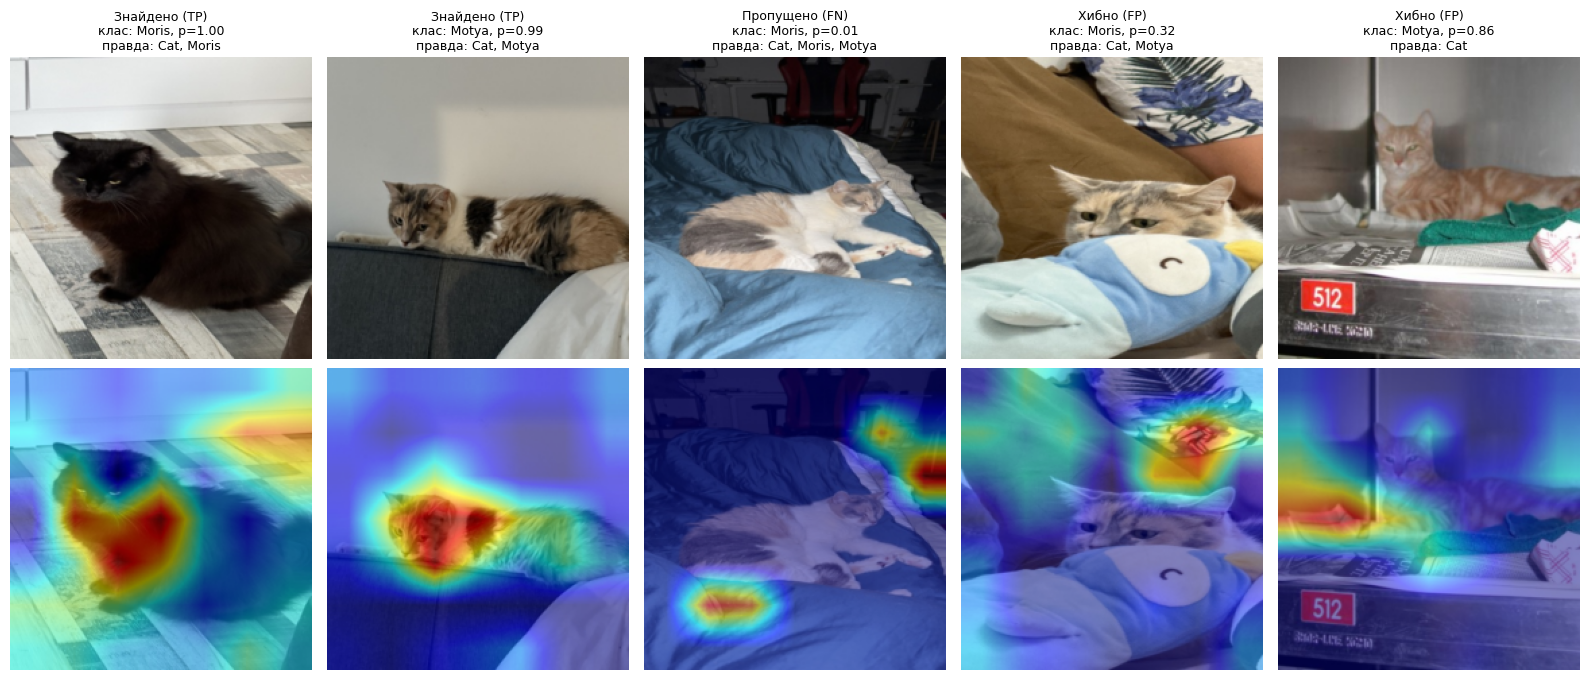

In [ ]:
res = pd.read_csv(RESULTS_CSV)
best = res.loc[res['val_map'].idxmax()]
EXP = best['exp_id']
cfg = json.loads(best['config'])
thr = best['rare_thr']
val_probs = np.load(f'{PREDS_DIR}/{EXP}_val.npy')

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = PetModel(cfg)
state = torch.load(f'{CKPT_DIR}/{EXP}.ckpt', map_location='cpu', weights_only=False)['state_dict']
state = {k.replace('net.', 'backbone.', 1) if k.startswith('net.') else k: v for k, v in state.items()}
model.load_state_dict(state)
model.eval().to(device)

if 'resnet' in cfg['model']:
    target_layer = model.backbone.layer4[-1]
elif 'efficientnet' in cfg['model']:
    target_layer = model.backbone.bn2
else:
    raise ValueError('add a target layer for this architecture')
cam = GradCAM(model=model, target_layers=[target_layer])

folds = pd.read_csv(FOLDS_CSV)
val_df = folds[folds['fold'] == 0].reset_index(drop=True)
picked = []
for c in ['Moris', 'Motya']:
    ci = CLASSES.index(c)
    true, prob = val_df[c].values, val_probs[:, ci]
    tp = np.where((true == 1) & (prob >= thr))[0]
    fn = np.where((true == 1) & (prob < thr))[0]
    fp = np.where((true == 0) & (prob >= thr))[0]
    tp = tp[np.argsort(-prob[tp])]
    fn = fn[np.argsort(prob[fn])]
    fp = fp[np.argsort(-prob[fp])]
    if len(tp):
        picked.append(('Found (TP)', tp[0], c))
    if len(fn):
        picked.append(('Missed (FN)', fn[0], c))
    if len(fp):
        picked.append(('False (FP)', fp[0], c))
order = {'Found (TP)': 0, 'Missed (FN)': 1, 'False (FP)': 2}
picked = sorted(picked, key=lambda t: order[t[0]])

val_tf = get_transforms(224, train=False)
plain_tf = T.Compose([T.Resize(224), T.CenterCrop(224)])

fig, axes = plt.subplots(2, len(picked), figsize=(3.2 * len(picked), 7), squeeze=False)
for j, (kind, i, c) in enumerate(picked):
    ci = CLASSES.index(c)
    img = Image.open(find_path(TRAIN_FILES, val_df.loc[i, ID_COL])).convert('RGB')
    rgb = np.array(plain_tf(img), dtype=np.float32) / 255.0
    x = val_tf(img).unsqueeze(0).to(device)

    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(ci)])[0]
    overlay = show_cam_on_image(rgb, heat, use_rgb=True)

    true_labels = [k for k in CLASSES if val_df.loc[i, k] == 1] or ['empty']
    axes[0, j].imshow(rgb)
    axes[0, j].axis('off')
    axes[0, j].set_title(f'{kind}\nclass: {c}, p={val_probs[i, ci]:.2f}\ntrue: {", ".join(true_labels)}', fontsize=9)
    axes[1, j].imshow(overlay)
    axes[1, j].axis('off')

plt.tight_layout()
plt.savefig(f'{OUT}/step25_gradcam_{EXP}.png', dpi=100, bbox_inches='tight')
plt.show()

**Conclusion:** in correct predictions GradCAM focuses on the animal itself (Moris's body, Motya's head), while the false positives are driven by the background (patterned fabric, a cage), so the model mostly learns the pet but partly relies on the setting.

**Is the model adequate?** exp06 reaches LB 0.863 against validation F1 0.894, a gap of about 2–3 rare-class mistakes, with no overfitting, stable gradients and attention on the animal, so the model is adequate; its weak spot is background-driven false positives.

## 8. Ensemble

In [ ]:
def ensemble(exp_ids, name):
    val = np.mean([np.load(f'{PREDS_DIR}/{e}_val.npy') for e in exp_ids], axis=0)
    test = np.mean([np.load(f'{PREDS_DIR}/{e}_test.npy') for e in exp_ids], axis=0)
    np.save(f'{PREDS_DIR}/{name}_val.npy', val)
    np.save(f'{PREDS_DIR}/{name}_test.npy', test)

    cfg = {'exp_id': name, 'note': 'ensemble ' + ' + '.join(exp_ids), 'members': exp_ids}
    thresholds = add_result(cfg, val)
    make_submission(test, thresholds, path=f'{OUT}/sub_{name}.csv')


ensemble(['exp06', 'exp02'], 'ens_06_02')
ensemble(['exp06', 'exp07'], 'ens_06_07')
ensemble(['exp06', 'exp07', 'exp02'], 'ens_06_07_02')

,F1 @0.5,F1 @thr,thr
Cat,0.993,0.993,0.50
Dog,0.991,0.991,0.50
Moris,0.800,0.870,0.15
Motya,0.714,0.783,0.15
Biatrix,0.200,0.875,0.15
MACRO,0.740,0.902,NaN


,F1 @0.5,F1 @thr,thr
Cat,0.995,0.995,0.50
Dog,0.993,0.993,0.50
Moris,0.857,0.909,0.45
Motya,0.800,0.875,0.45
Biatrix,0.714,0.714,0.45
MACRO,0.872,0.897,NaN


,F1 @0.5,F1 @thr,thr
Cat,0.995,0.996,0.5
Dog,0.992,0.993,0.5
Moris,0.737,0.833,0.2
Motya,0.200,0.696,0.2
Biatrix,0.500,0.941,0.2
MACRO,0.685,0.892,NaN


In [ ]:
res = pd.read_csv(RESULTS_CSV).set_index('exp_id')
rows = ['exp02', 'exp06', 'exp07', 'ens_06_02', 'ens_06_07', 'ens_06_07_02']
display(res.loc[[r for r in rows if r in res.index],
                ['change', 'val_map', 'AP_Moris', 'AP_Motya', 'AP_Biatrix', 'rare_thr', 'F1@thr', 'LB']])

,change,val_map,AP_Moris,AP_Motya,AP_Biatrix,rare_thr,F1@thr,LB
exp_id,,,,,,,,
exp02,lr 3e-4,0.6521,0.6158,0.2350,0.4131,0.10,0.6151,NaN
exp06,efficientnet_b0 (settings exp02),0.9362,0.9063,0.8763,0.8998,0.25,0.8938,NaN
exp07,GeM + head (base exp06),0.9321,0.8777,0.8116,0.9722,0.20,0.8677,NaN
ens_06_02,ensemble exp06 + exp02,0.9421,0.9373,0.8677,0.9067,0.15,0.9024,NaN
ens_06_07,ensemble exp06 + exp07,0.9725,0.9343,0.9288,1.0000,0.45,0.8973,NaN
ens_06_07_02,ensemble exp06 + exp07 + exp02,0.9659,0.9369,0.9046,0.9889,0.20,0.8917,NaN


**Conclusion:** averaging exp06 and exp07 raises val mAP from 0.936 to 0.973 because the two models are strong on different rare classes, but validation F1 stays at the same level (0.897 vs 0.894) and on LB this ensemble is worse (0.839 vs 0.863); exp06 + ResNet-18 gives the best LB (0.864), within noise of exp06.

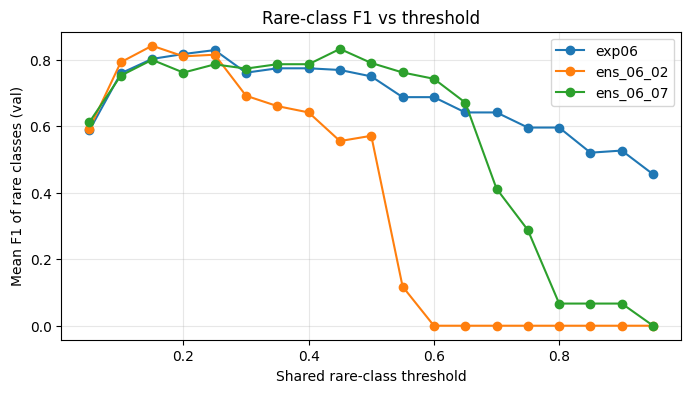

In [ ]:
val_true = np.load(f'{PREDS_DIR}/val_true.npy')
grid = np.round(np.arange(0.05, 0.96, 0.05), 2)
rare_idx = [CLASSES.index(c) for c in RARE]

plt.figure(figsize=(8, 4))
for e in ['exp06', 'ens_06_02', 'ens_06_07']:
    p = np.load(f'{PREDS_DIR}/{e}_val.npy')
    curve = [np.mean([f1_score(val_true[:, i], (p[:, i] >= t).astype(int), zero_division=0)
                      for i in rare_idx]) for t in grid]
    plt.plot(grid, curve, marker='o', label=e)
plt.xlabel('Shared rare-class threshold')
plt.ylabel('Mean F1 of rare classes (val)')
plt.title('Rare-class F1 vs threshold')
plt.legend()
plt.grid(alpha=.3)
plt.savefig(f'{OUT}/step27_thr_curves.png', dpi=100, bbox_inches='tight')
plt.show()

**Conclusion:** for ens_06_07 the F1 curve is a wide plateau (0.76–0.83 for thresholds 0.10–0.60), so its tuned threshold of 0.45 was decided by one or two validation photos, which most likely explains why this ensemble lost on LB.

## 9. Validation vs leaderboard

In [ ]:
set_lb('exp01', 0.4126)
set_lb('exp06', 0.86307)
set_lb('ens_06_07', 0.83909)
set_lb('ens_06_02', 0.86448)
show_results()

,exp_id,change,val_map,AP_Cat,AP_Dog,AP_Moris,AP_Motya,AP_Biatrix,F1@0.5,rare_thr,F1@thr,LB
0,exp01,baseline,0.4287,0.9919,0.9931,0.0887,0.0207,0.0490,0.3821,0.20,0.4571,0.41260
1,exp02,lr 3e-4,0.6521,0.9986,0.9980,0.6158,0.2350,0.4131,0.3923,0.10,0.6151,NaN
2,exp03,"SGD momentum 0.9, lr 1e-2",0.4004,0.9891,0.9855,0.0113,0.0037,0.0122,0.3777,0.05,0.3764,NaN
3,exp04,OneCycle instead of cosine,0.4329,0.9926,0.9934,0.0996,0.0266,0.0525,0.3828,0.20,0.4543,NaN
4,exp05,oversampling rare ×10,0.5916,0.9919,0.9910,0.6230,0.1558,0.1961,0.3824,0.30,0.5711,NaN
5,exp06,efficientnet_b0 (settings exp02),0.9362,0.9996,0.9990,0.9063,0.8763,0.8998,0.8463,0.25,0.8938,0.86307
6,exp07,GeM + head (base exp06),0.9321,0.9998,0.9994,0.8777,0.8116,0.9722,0.6876,0.20,0.8677,NaN
7,ens_06_02,ensemble exp06 + exp02,0.9421,0.9997,0.9993,0.9373,0.8677,0.9067,0.7396,0.15,0.9024,0.86448
8,ens_06_07,ensemble exp06 + exp07,0.9725,0.9998,0.9995,0.9343,0.9288,1.0000,0.8718,0.45,0.8973,0.83909
9,ens_06_07_02,ensemble exp06 + exp07 + exp02,0.9659,0.9998,0.9995,0.9369,0.9046,0.9889,0.6849,0.20,0.8917,NaN


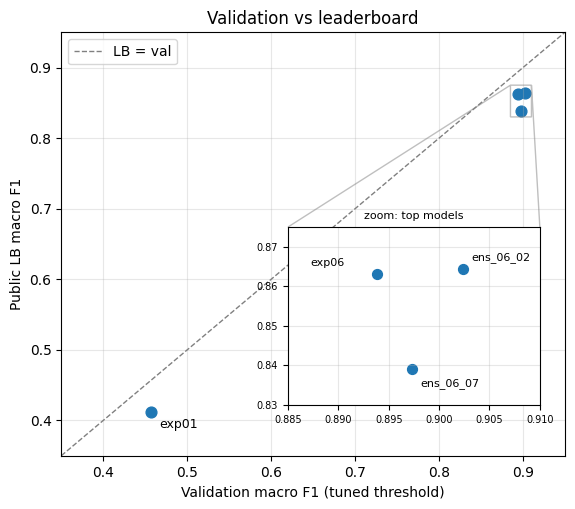

In [ ]:
res = pd.read_csv(RESULTS_CSV).dropna(subset=['LB'])
offsets = {'exp01': (6, -12), 'exp06': (-48, 6), 'ens_06_02': (6, 6), 'ens_06_07': (6, -12)}

fig, ax = plt.subplots(figsize=(6.5, 5.5))
lims = [0.35, 0.95]
ax.plot(lims, lims, '--', color='grey', lw=1, label='LB = val')
ax.scatter(res['F1@thr'], res['LB'], s=60)
ax.annotate('exp01', (res.loc[res.exp_id == 'exp01', 'F1@thr'].item(),
                      res.loc[res.exp_id == 'exp01', 'LB'].item()),
            textcoords='offset points', xytext=offsets['exp01'], fontsize=9)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Validation macro F1 (tuned threshold)')
ax.set_ylabel('Public LB macro F1')
ax.set_title('Validation vs leaderboard')
ax.legend(loc='upper left')
ax.grid(alpha=.3)

ins = ax.inset_axes([0.45, 0.12, 0.5, 0.42])
top = res[res.exp_id != 'exp01']
ins.plot([0.8, 1], [0.8, 1], '--', color='grey', lw=1)
ins.scatter(top['F1@thr'], top['LB'], s=50)
for _, r in top.iterrows():
    ins.annotate(r['exp_id'], (r['F1@thr'], r['LB']), textcoords='offset points',
                 xytext=offsets[r['exp_id']], fontsize=8)
ins.set_xlim(0.885, 0.91)
ins.set_ylim(0.83, 0.875)
ins.tick_params(labelsize=7)
ins.grid(alpha=.3)
ins.set_title('zoom: top models', fontsize=8)
ax.indicate_inset_zoom(ins, edgecolor='grey')

plt.savefig(f'{OUT}/val_vs_lb.png', dpi=100, bbox_inches='tight')
plt.show()

**Conclusion:** large improvements transfer from validation to LB (baseline → EfficientNet: +0.44 on validation, +0.45 on LB), LB is systematically 0.03–0.06 lower because thresholds are tuned on the validation fold, and the three top submissions differ by less than one rare-class mistake, so their LB order is effectively noise.